### **Movie Recommendation System**
Recommends movies based on user preferences and ratings.

Dataset: MovieLens Latest Small.

Tech Stack: Python, Pandas, NumPy, Matplotlib, Scikit-learn.

Techniques: Popularity-based filtering, Content-based filtering, Collaborative filtering, KNN, and SVD.

Evaluation: RMSE, Precision@K, Recall@K, and NDCG@K.

Goal: Build and compare recommendation models to provide personalized movie suggestions.




### **Extract the dataset**

In [2]:
import zipfile
import os

zip_path = "/content/ml-latest-small.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/")

print("Dataset extracted successfully!")
print(os.listdir("/content/ml-latest-small"))


Dataset extracted successfully!
['links.csv', 'ratings.csv', 'movies.csv', 'README.txt', 'tags.csv']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

**Import Libraries**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

print("Libraries imported successfully!")


Libraries imported successfully!


**Load the data:** loading the dataset into Pandas DataFrames so you can work with the information.

In [5]:

data_path = "/content/ml-latest-small/"

movies = pd.read_csv(data_path + "movies.csv")
ratings = pd.read_csv(data_path + "ratings.csv")
tags = pd.read_csv(data_path + "tags.csv")

print("Movies shape:", movies.shape)
print("Ratings shape:", ratings.shape)
print("Tags shape:", tags.shape)

display(movies.head())
display(ratings.head())


Movies shape: (9742, 3)
Ratings shape: (100836, 4)
Tags shape: (3683, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [6]:
#Explore the data
print("Missing values in movies:")
print(movies.isnull().sum())

print("\nMissing values in ratings:")
print(ratings.isnull().sum())

print("\nRating distribution:")
print(ratings["rating"].value_counts().sort_index())

print("\nNumber of unique users:", ratings["userId"].nunique())
print("Number of unique movies rated:", ratings["movieId"].nunique())


Missing values in movies:
movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Rating distribution:
rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

Number of unique users: 610
Number of unique movies rated: 9724


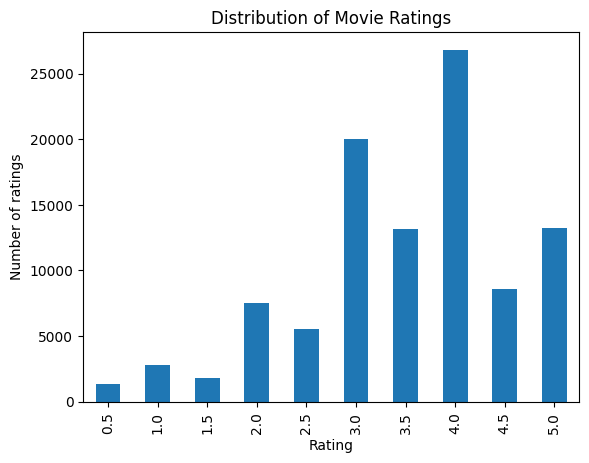

In [7]:
#plot the distribution
ratings["rating"].value_counts().sort_index().plot(
    kind="bar",
    title="Distribution of Movie Ratings"
)

plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.show()


In [8]:
#simple recommendation baseline

movie_stats = ratings.groupby("movieId").agg(
    average_rating=("rating", "mean"),
    rating_count=("rating", "count")
).reset_index()

popular_movies = movie_stats.merge(
    movies[["movieId", "title"]],
    on="movieId"
)

# Recommend movies with at least 50 ratings
popular_movies = popular_movies[
    popular_movies["rating_count"] >= 50
]

popular_movies = popular_movies.sort_values(
    ["average_rating", "rating_count"],
    ascending=False
)

display(
    popular_movies[
        ["title", "average_rating", "rating_count"]
    ].head(10)
)


,title,average_rating,rating_count
277,"Shawshank Redemption, The (1994)",4.429022,317
659,"Godfather, The (1972)",4.289062,192
2224,Fight Club (1999),4.272936,218
974,Cool Hand Luke (1967),4.271930,57
602,Dr. Strangelove or: How I Learned to Stop Worr...,4.268041,97
686,Rear Window (1954),4.261905,84
921,"Godfather: Part II, The (1974)",4.259690,129
6298,"Departed, The (2006)",4.252336,107
913,Goodfellas (1990),4.250000,126
694,Casablanca (1942),4.240000,100
